In [ ]:
#import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler,LabelEncoder
from sklearn.impute import SimpleImputer

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#load the dataset
df=pd.read_csv('/content/Social_Media_Sentiment_Analysis_AI_Trends_2026.csv')
print('Dataset loaded successfully')

Dataset loaded successfully


In [ ]:
df.shape

(2200, 27)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Columns: 208 entries, platform to sentiment_score_182
dtypes: bool(187), float64(2), int64(5), object(14)
memory usage: 762.8+ KB


In [ ]:
df.describe()

,user_followers_count,post_length,like_count,comment_count,share_count,engagement_score,sentiment_score,toxicity_score
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,251563.535455,31.432273,10009.355909,2475.158636,1471.210455,0.508855,0.010514,0.501041
std,143956.859442,3.764069,5885.532782,1425.979361,877.520927,0.293027,0.556477,0.284087
min,139.000000,25.000000,11.000000,0.000000,0.000000,0.000000,-1.000000,0.000000
25%,127377.750000,29.000000,4859.500000,1239.250000,700.750000,0.260000,-0.450000,0.260000
50%,246535.500000,31.000000,9758.500000,2437.500000,1458.000000,0.520000,0.010000,0.500000
75%,375852.000000,36.000000,15310.000000,3725.750000,2238.250000,0.760000,0.472500,0.740000
max,499778.000000,36.000000,20000.000000,5000.000000,3000.000000,1.000000,1.000000,1.000000


In [ ]:
df.isnull().sum()

,0
platform,0
post_id,0
user_id,0
username,0
user_verified,0
user_followers_count,0
user_location,0
post_text,0
language,0
hashtags,0


In [ ]:
df.mentions.fillna('', inplace=True)

In [ ]:
#drop mentions and check null values
df.drop('mentions',axis=1,inplace=True)

In [ ]:
#create labelEncoder
le=LabelEncoder()
#Apply labelEncoding to column
df['sentiment_score']=le.fit_transform(df['sentiment_score'])
print(df['sentiment_score'])

0       164
1        89
2       144
3       105
4        86
       ... 
2195     98
2196    106
2197     10
2198    173
2199     72
Name: sentiment_score, Length: 2200, dtype: int64


In [ ]:
#Apply one hot encoding
df=pd.get_dummies(df,columns=['sentiment_score'])
print(df.head())

  platform    post_id    user_id  username  user_verified  \
0  YouTube  YO_100000  user_2679  rxckafna           True   
1   Reddit  RE_100001  user_3045  zjovqwps           True   
2  YouTube  YO_100002  user_4598  rvufaigf          False   
3  Twitter  TW_100003  user_3504  qukbjznz           True   
4  YouTube  YO_100004  user_3646  ounaiayw          False   

   user_followers_count user_location                             post_text  \
0                375410       Germany       I don’t agree with this at all.   
1                346702            UK             Worst decision ever made.   
2                111487       Germany    This trend is getting out of hand.   
3                356674       Germany      Pretty neutral about the update.   
4                125551           USA  Loved the explanation, very helpful.   

  language       hashtags  ... sentiment_score_0.91  sentiment_score_0.92  \
0       ur  #news,#update  ...                False                 False   
1   

In [ ]:
#Normalization(MinMax)
scaler = MinMaxScaler()

num_cols = ['user_followers_count', 'post_length', 'like_count', 'comment_count', 'share_count', 'engagement_score', 'toxicity_score']

df_scaled = df.copy()
df_scaled[num_cols] = scaler.fit_transform(df[num_cols])
print(df.head())

  platform    post_id    user_id  username  user_verified  \
0  YouTube  YO_100000  user_2679  rxckafna           True   
1   Reddit  RE_100001  user_3045  zjovqwps           True   
2  YouTube  YO_100002  user_4598  rvufaigf          False   
3  Twitter  TW_100003  user_3504  qukbjznz           True   
4  YouTube  YO_100004  user_3646  ounaiayw          False   

   user_followers_count user_location                             post_text  \
0                375410       Germany       I don’t agree with this at all.   
1                346702            UK             Worst decision ever made.   
2                111487       Germany    This trend is getting out of hand.   
3                356674       Germany      Pretty neutral about the update.   
4                125551           USA  Loved the explanation, very helpful.   

  language       hashtags  ...  sentiment_score_173  sentiment_score_174  \
0       ur  #news,#update  ...                False                False   
1     

In [ ]:
#Create a column(new feature)
df['total_interactions'] = df['like_count'] + df['comment_count'] + df['share_count']

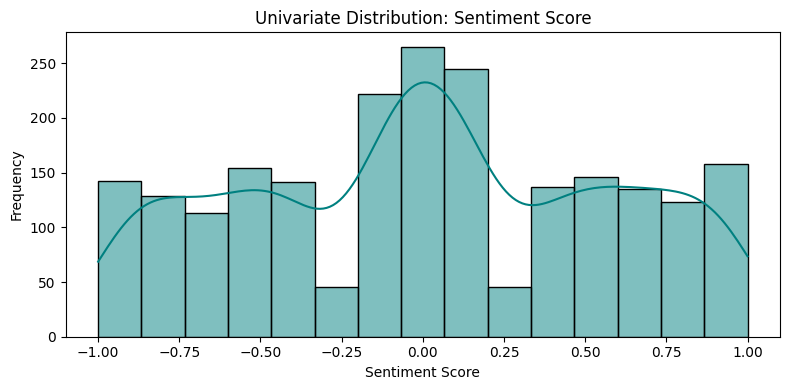

In [ ]:
# 1. Univariate Distribution (Sentiment Score)
plt.figure(figsize=(8, 4))
sns.histplot(df['sentiment_score'], kde=True, color='teal')
plt.title('Univariate Distribution: Sentiment Score')
plt.xlabel('Sentiment Score')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

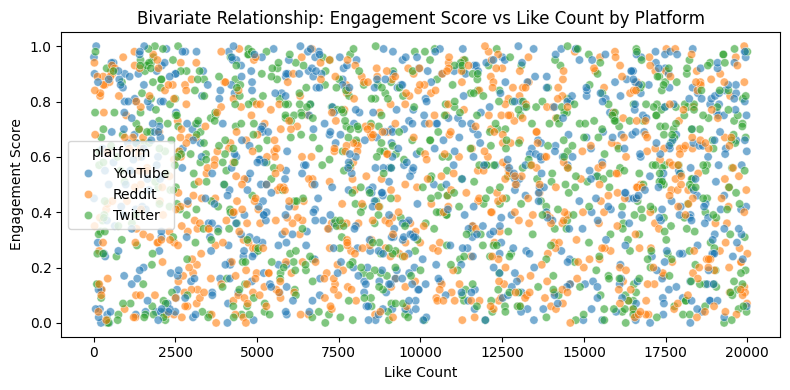

In [ ]:
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x='like_count', y='engagement_score', hue='platform', alpha=0.6)
plt.title('Bivariate Relationship: Engagement Score vs Like Count by Platform')
plt.xlabel('Like Count')
plt.ylabel('Engagement Score')
plt.tight_layout()
plt.show()

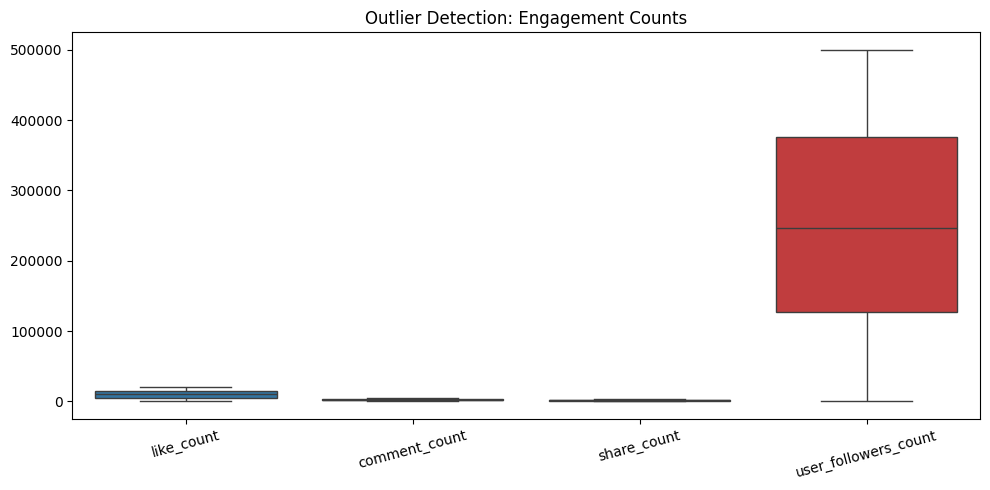

In [ ]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df[['like_count', 'comment_count', 'share_count', 'user_followers_count']])
plt.title('Outlier Detection: Engagement Counts')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()